<a href="https://colab.research.google.com/github/OshadhaVihanga/Convolutional-Neural-Networks/blob/main/230481E_a03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PERERA K W A O V   230481E

**EN3160 Assignment 3 on Neural Networks**

Github repository : https://github.com/OshadhaVihanga/Convolutional-Neural-Networks

In [1]:
import torch, torchvision
print(torch.__version__, torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

2.11.0+cu130 0.26.0+cu130
GPU available: True


In [2]:
!wget https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip -q hymenoptera_data.zip

--2026-10-18 11:37:52--  https://download.pytorch.org/tutorial/hymenoptera_data.zip
Resolving download.pytorch.org (download.pytorch.org)... 99.84.215.89, 99.84.215.85, 99.84.215.59, ...
Connecting to download.pytorch.org (download.pytorch.org)|99.84.215.89|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47286322 (45M) [application/zip]
Saving to: ‘hymenoptera_data.zip’

hymenoptera_data.zi 100%[===================>]  45.10M   140MB/s    in 0.3s    

2026-10-18 11:37:52 (140 MB/s) - ‘hymenoptera_data.zip’ saved [47286322/47286322]



QUESTION 1


100%|██████████| 170M/170M [59:40<00:00, 47.6kB/s]


Epoch 1/10, Loss: 2.2080
Epoch 2/10, Loss: 2.0246
Epoch 3/10, Loss: 1.9463
Epoch 4/10, Loss: 1.9047
Epoch 5/10, Loss: 1.8761
Epoch 6/10, Loss: 1.8532
Epoch 7/10, Loss: 1.8346
Epoch 8/10, Loss: 1.8199
Epoch 9/10, Loss: 1.8077
Epoch 10/10, Loss: 1.7974


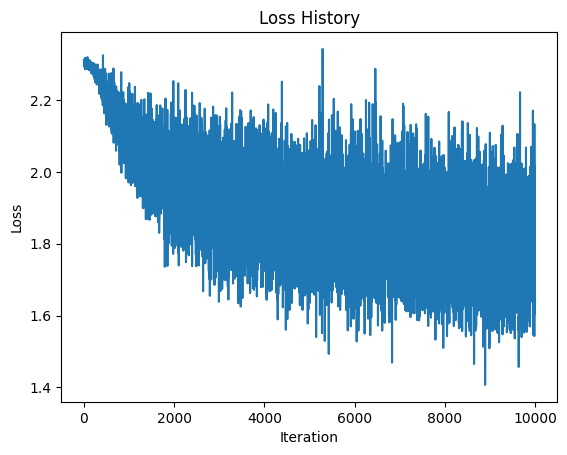

Training accuracy: 36.78%
Test accuracy: 37.16%


In [3]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Data loading (same as given)
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Network parameters
Din = 3 * 32 * 32   # input size
H = 100             # middle layer nodes (new)
K = 10              # output classes
std = 1e-2          # changed from 1e-5

# Layer 1: input -> middle (new), Layer 2: middle -> output
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     # changed from 20 (10 epochs)
lr = 1e-2           # changed from 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)      # middle layer + sigmoid
        scores = h.mm(w2) + b2                      # output layer
        scores = scores - scores.max(dim=1, keepdim=True)[0]  # for stability
        exp_scores = torch.exp(scores)
        probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)  # softmax

        # Cross-entropy loss
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation (chain rule, output to input)
        dscores = (probs - y_train_onehot) / Ntr    # softmax + CE gradient
        dw2 = h.t().mm(dscores) + 2 * reg * w2
        db2 = dscores.sum(dim=0)
        dh = dscores.mm(w2.t())                     # gradient to middle layer
        dz1 = dh * h * (1 - h)                      # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader):.4f}")
    lr *= lr_decay   # learning rate decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Accuracy function
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            out = torch.sigmoid(x.mm(w1) + b1).mm(w2) + b2
            pred = torch.argmax(out, dim=1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()
    return 100 * correct / total

print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")

**Discussion : Results**

- Final loss: 1.7974
- Training accuracy: 36.78%
- Test accuracy: 37.16%

**Loss curve**

- Loss started at about 2.30, which is ln(10). This is random guessing over 10 classes.
- Epoch loss fell from 2.21 to 1.80 over 10 epochs.
- Loss was still falling at epoch 10, so training had not converged.
- The per-iteration plot is noisy because each update uses a small batch of 50 (SGD).
- The downward trend is clear.

**Accuracy**

- Training and test accuracy are almost equal (36.78% vs 37.16%).
- There is no overfitting.
- The model underfits, since even the training accuracy is low.
- It is well above the 10% of random guessing, so it has learned useful features.

**Why accuracy is low**

- Flattening the image to 3072 values destroys spatial structure.
- Only one hidden layer (100 nodes) with sigmoid, which learns slowly.
- Only 10 epochs of plain SGD with learning rate decay.
- Fully connected layers have no weight sharing, so they cannot detect local patterns like edges.

**Effect of the changes**

- The sigmoid middle layer adds non-linearity. Without it, two layers collapse into one linear classifier.
- Cross-entropy with softmax gives a simple gradient, (probs − onehot) / N, which suits classification.
- I increased the weight std and learning rate from the given values (1e-5, 2e-6). The given values were too small for the network to learn in 10 epochs.

QUESTION 2

Device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 496kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.73MB/s]



LeNet-5: 61706 parameters
Epoch 1/10 | Train loss 0.0889 acc 97.43% | Test loss 0.0901 acc 97.30%
Epoch 2/10 | Train loss 0.0502 acc 98.45% | Test loss 0.0572 acc 98.14%
Epoch 3/10 | Train loss 0.0367 acc 98.86% | Test loss 0.0544 acc 98.19%
Epoch 4/10 | Train loss 0.0296 acc 99.08% | Test loss 0.0488 acc 98.40%
Epoch 5/10 | Train loss 0.0222 acc 99.28% | Test loss 0.0417 acc 98.69%
Epoch 6/10 | Train loss 0.0202 acc 99.39% | Test loss 0.0442 acc 98.71%
Epoch 7/10 | Train loss 0.0198 acc 99.36% | Test loss 0.0464 acc 98.52%
Epoch 8/10 | Train loss 0.0140 acc 99.56% | Test loss 0.0426 acc 98.67%
Epoch 9/10 | Train loss 0.0117 acc 99.63% | Test loss 0.0382 acc 98.70%
Epoch 10/10 | Train loss 0.0108 acc 99.65% | Test loss 0.0450 acc 98.72%

Small CNN: 113610 parameters
Epoch 1/10 | Train loss 0.0396 acc 98.72% | Test loss 0.0396 acc 98.73%
Epoch 2/10 | Train loss 0.0269 acc 99.12% | Test loss 0.0332 acc 99.01%
Epoch 3/10 | Train loss 0.0193 acc 99.38% | Test loss 0.0267 acc 99.27%
Epoch 

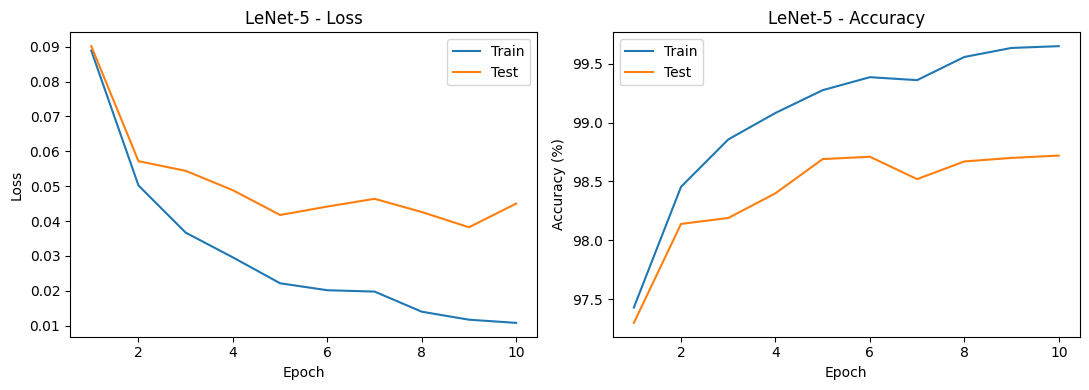

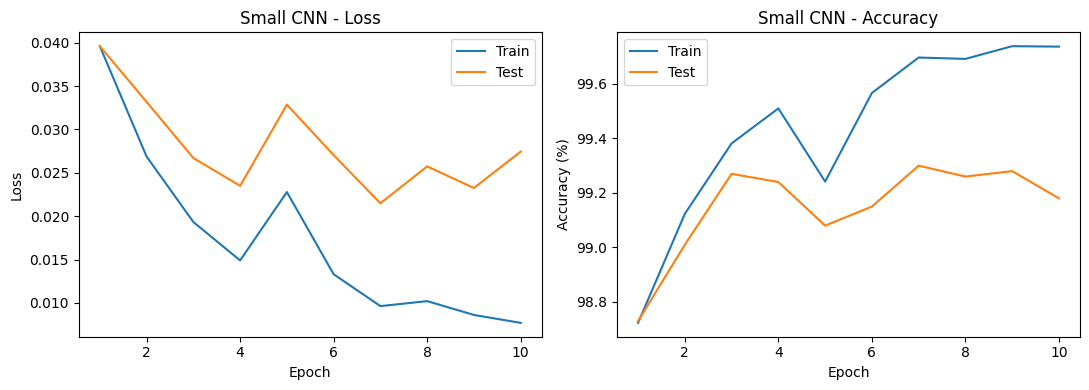

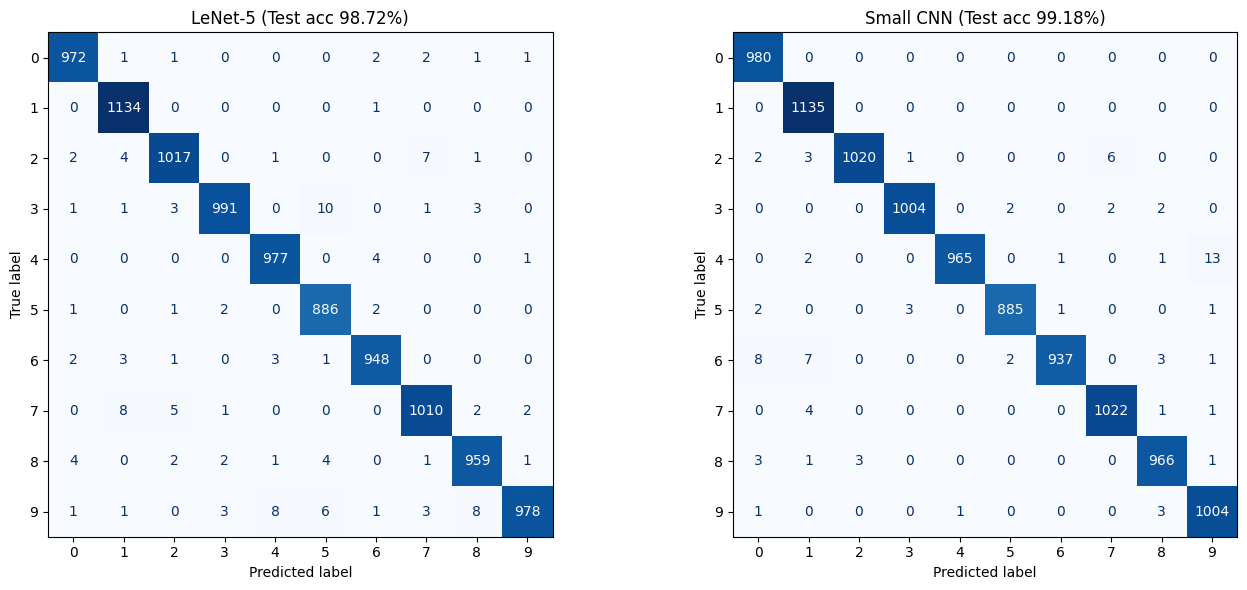


Final results after 10 epochs
LeNet-5   : Train 99.65% | Test 98.72%
Small CNN : Train 99.74% | Test 99.18%


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 1. Data (resize to 32x32 as in LeNet-5)
transform = transforms.Compose([
    transforms.Resize(32),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])
trainset = torchvision.datasets.MNIST('./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST('./data', train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False, num_workers=2)

# 2a. LeNet-5 (avg pooling, tanh, FC at the end)
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2, 2),     # 6x14x14
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2, 2))    # 16x5x5
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(400, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

# 2b. Small modern CNN (3 conv + BatchNorm + Dropout)
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))  # 128x4x4
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 4 * 4, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

# 3. Evaluate: returns loss, accuracy, predictions, labels
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    preds, labels_all = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            p = out.argmax(1)
            correct += (p == y).sum().item()
            n += y.size(0)
            preds.append(p.cpu()); labels_all.append(y.cpu())
    return total_loss / n, 100 * correct / n, torch.cat(preds).numpy(), torch.cat(labels_all).numpy()

# 4. Train for 10 epochs and log per-epoch results
def train_model(model, name, epochs=10):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    h = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    print(f"\n{name}: {sum(p.numel() for p in model.parameters())} parameters")
    for ep in range(epochs):
        model.train()
        for x, y in trainloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
        # evaluate both sets in eval mode (fair comparison)
        tr_l, tr_a, _, _ = evaluate(model, trainloader, criterion)
        te_l, te_a, _, _ = evaluate(model, testloader, criterion)
        for k, v in zip(h.keys(), [tr_l, tr_a, te_l, te_a]):
            h[k].append(v)
        print(f"Epoch {ep+1}/{epochs} | Train loss {tr_l:.4f} acc {tr_a:.2f}% | "
              f"Test loss {te_l:.4f} acc {te_a:.2f}%")
    return model, h

lenet, h_lenet = train_model(LeNet5(), "LeNet-5")
cnn, h_cnn = train_model(SmallCNN(), "Small CNN")

# 5. Plots: loss and accuracy per epoch
def plot_history(h, name):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, h["train_loss"], label="Train"); ax[0].plot(ep, h["test_loss"], label="Test")
    ax[0].set_title(f"{name} - Loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="Train"); ax[1].plot(ep, h["test_acc"], label="Test")
    ax[1].set_title(f"{name} - Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(h_lenet, "LeNet-5")
plot_history(h_cnn, "Small CNN")

# 6. Confusion matrices on the test set
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (m, name) in zip(ax, [(lenet, "LeNet-5"), (cnn, "Small CNN")]):
    _, acc, p, y = evaluate(m, testloader, nn.CrossEntropyLoss())
    cm = confusion_matrix(y, p)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{name} (Test acc {acc:.2f}%)")
plt.tight_layout(); plt.show()

# 7. Final summary
print("\nFinal results after 10 epochs")
print(f"LeNet-5   : Train {h_lenet['train_acc'][-1]:.2f}% | Test {h_lenet['test_acc'][-1]:.2f}%")
print(f"Small CNN : Train {h_cnn['train_acc'][-1]:.2f}% | Test {h_cnn['test_acc'][-1]:.2f}%")

**Discussion : Results (10 epochs)**

- LeNet-5: Train 99.65%, Test 98.72% (61,706 parameters)
- Small CNN: Train 99.74%, Test 99.18% (113,610 parameters)

**Loss and accuracy curves**

- Both models pass 97% accuracy in epoch 1, since convolution keeps spatial structure and shares weights.
- Train loss falls steadily for both. Test loss flattens after about epoch 5.
- The Small CNN dips at epoch 5, which is normal noise from Adam and is recovered by epoch 6.

**Overfitting**

- Train-test gap is about 0.9% for LeNet-5 and 0.6% for the Small CNN.
- Both overfit mildly. Dropout and batch norm reduce it but do not remove it.

**Why the Small CNN is better**

- Batch norm gives faster, more stable training.
- ReLU avoids tanh saturation.
- More filters (32, 64, 128) learn richer features.
- It has about twice the parameters, so part of the gain comes from model size.

**Conclusion**

- Both models are far better than the fully connected network in Q1.
- The Small CNN gives the best test accuracy (99.18%).

QUESTION 3

Device: cuda
Classes: ['ants', 'bees'] | Sizes: {'train': 244, 'val': 153}

 Fine-tuning 
Epoch 1/25 | Train loss 0.5441 acc 73.77% | Val loss 0.3096 acc 88.89%
Epoch 5/25 | Train loss 0.6164 acc 78.28% | Val loss 0.4953 acc 84.97%
Epoch 10/25 | Train loss 0.3852 acc 85.25% | Val loss 0.1982 acc 92.16%
Epoch 15/25 | Train loss 0.2818 acc 86.48% | Val loss 0.1591 acc 92.81%
Epoch 20/25 | Train loss 0.2380 acc 89.34% | Val loss 0.1625 acc 93.46%
Epoch 25/25 | Train loss 0.2983 acc 87.30% | Val loss 0.1529 acc 93.46%
Time: 73s | Best val acc: 94.12%

 Feature extractor
Epoch 1/25 | Train loss 0.5609 acc 71.72% | Val loss 0.2482 acc 91.50%
Epoch 5/25 | Train loss 0.6222 acc 75.00% | Val loss 0.2304 acc 92.81%
Epoch 10/25 | Train loss 0.3453 acc 82.79% | Val loss 0.1729 acc 95.42%
Epoch 15/25 | Train loss 0.2952 acc 88.11% | Val loss 0.1723 acc 94.12%
Epoch 20/25 | Train loss 0.3717 acc 83.20% | Val loss 0.1519 acc 95.42%
Epoch 25/25 | Train loss 0.3203 acc 85.25% | Val loss 0.1659 acc 95.4

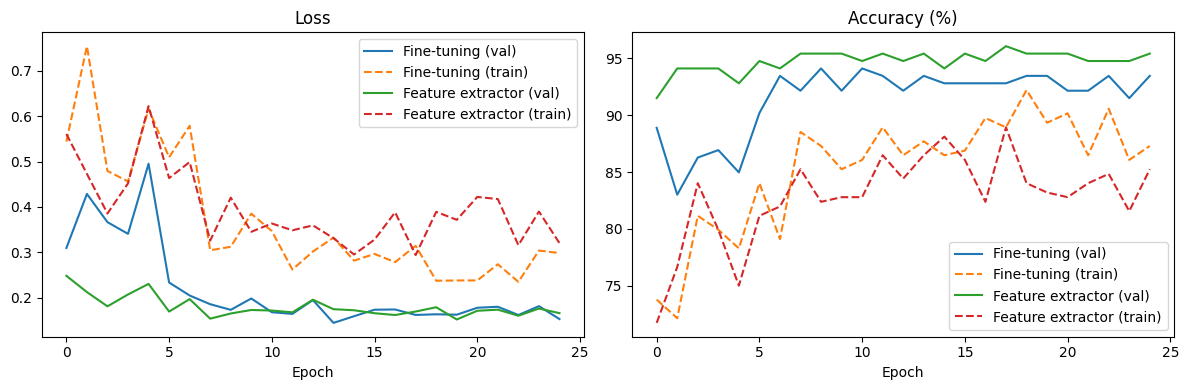


Final results (best validation accuracy)
Fine-tuning       : 94.12%
Feature extractor : 96.08%


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time, copy

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 1. Data (same transforms as the PyTorch tutorial)
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]),
}
data_dir = 'hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(f"{data_dir}/{x}", data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                              shuffle=True, num_workers=2)
               for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes
print("Classes:", class_names, "| Sizes:", dataset_sizes)

# 2. Training function (keeps the best model on validation set)
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    best_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.time()
    for epoch in range(num_epochs):
        for phase in ['train', 'val']:
            model.train() if phase == 'train' else model.eval()
            run_loss, run_corrects = 0.0, 0
            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    preds = outputs.argmax(1)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                run_loss += loss.item() * inputs.size(0)
                run_corrects += (preds == labels).sum().item()
            if phase == 'train':
                scheduler.step()
            ep_loss = run_loss / dataset_sizes[phase]
            ep_acc = 100 * run_corrects / dataset_sizes[phase]
            hist[f"{phase}_loss"].append(ep_loss)
            hist[f"{phase}_acc"].append(ep_acc)
            if phase == 'val' and ep_acc > best_acc:
                best_acc = ep_acc
                best_wts = copy.deepcopy(model.state_dict())
        if (epoch + 1) % 5 == 0 or epoch == 0:
          print(f"Epoch {epoch+1}/{num_epochs} | "
            f"Train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.2f}% | "
            f"Val loss {hist['val_loss'][-1]:.4f} acc {hist['val_acc'][-1]:.2f}%")
    print(f"Time: {time.time()-start:.0f}s | Best val acc: {best_acc:.2f}%")
    model.load_state_dict(best_wts)
    return model, hist, best_acc

# 3a. Fine-tuning: all layers are trained
model_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model_ft.fc = nn.Linear(model_ft.fc.in_features, 2)   # new 2-class layer
model_ft = model_ft.to(device)
criterion = nn.CrossEntropyLoss()
opt_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
sched_ft = lr_scheduler.StepLR(opt_ft, step_size=7, gamma=0.1)
print("\n Fine-tuning ")
model_ft, hist_ft, best_ft = train_model(model_ft, criterion, opt_ft, sched_ft)

# 3b. Feature extractor: freeze all layers, train only the new fc layer
model_fe = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in model_fe.parameters():
    p.requires_grad = False                            # freeze
model_fe.fc = nn.Linear(model_fe.fc.in_features, 2)    # new layer (trainable)
model_fe = model_fe.to(device)
opt_fe = optim.SGD(model_fe.fc.parameters(), lr=0.001, momentum=0.9)
sched_fe = lr_scheduler.StepLR(opt_fe, step_size=7, gamma=0.1)
print("\n Feature extractor")
model_fe, hist_fe, best_fe = train_model(model_fe, criterion, opt_fe, sched_fe)

# 4. Plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for h, name in [(hist_ft, "Fine-tuning"), (hist_fe, "Feature extractor")]:
    ax[0].plot(h["val_loss"], label=f"{name} (val)")
    ax[0].plot(h["train_loss"], "--", label=f"{name} (train)")
    ax[1].plot(h["val_acc"], label=f"{name} (val)")
    ax[1].plot(h["train_acc"], "--", label=f"{name} (train)")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].set_title("Accuracy (%)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

# 5. Summary
print("\nFinal results (best validation accuracy)")
print(f"Fine-tuning       : {best_ft:.2f}%")
print(f"Feature extractor : {best_fe:.2f}%")

**Training behaviour**

- Both start with high validation accuracy (88.9% and 91.5% in epoch 1). The pretrained ImageNet features already separate ants and bees well.
- Validation loss falls to about 0.15 to 0.17 for both.
- Fine-tuning is noisier early on (val accuracy is only 84.97% at epoch 5, compared with 92.81% for the feature extractor) because all layers are updated with a small batch size of 4.
- The curves become smoother after epoch 7, when the learning rate decays by 0.1.

**Train vs validation**

- Validation accuracy is higher than training accuracy for both models. This is not a bug.
- Training uses random crops and flips (harder images), while validation uses a fixed centre crop.
- There is no overfitting, so both models generalise well.

**Fine-tuning vs feature extractor**

- The feature extractor scored about 2% higher (96.08% vs 94.12%).
- The dataset is tiny (244 train images). Training all 11M parameters on so little data can disturb good pretrained features.
- The feature extractor trains only the final layer (1,026 parameters). It keeps the ImageNet features intact and has less risk of overfitting.
- It is also faster, since gradients are not computed for the frozen layers.
- On 153 validation images, the gap is about 3 images. A different seed could change the ranking.

**Conclusion**

- Transfer learning works very well here. Both methods reach above 94% from only 244 images.
- For a small dataset similar to ImageNet, the feature extractor is the better and cheaper choice.
- Fine-tuning would help more with larger datasets or images very different from ImageNet.